### Setting up the binary asteroid system

Initial conditions from https://en.wikipedia.org/wiki/Dimorphos

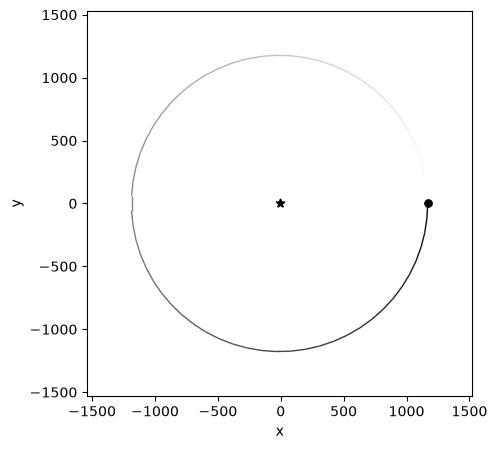

In [25]:
import rebound
import numpy as np
import matplotlib.pyplot as plt

sim = rebound.Simulation()

# Can change the integrator used
sim.integrator = "whfast"
#sim.integrator = "ias15"

# Changes units in simulation to SI units 
sim.G = 6.6743e-11 # m^3 / kg s^2

sim.add(m=5.2e11) # Didymos

P0 = 11.921473 * 60 * 60
sim.add(m=4.3e9, P=P0, e=0) # Dimorphos 

sim.dt = P0 / 1000 

sim.move_to_com() 

%matplotlib inline
op = rebound.OrbitPlot(sim)

#sim.status()

### DART Impact

**The Model**

From conservation of momentum, we have

$ m_D v_{i,D} + m_s v_{i,s} = m_D v_{f,D} + \gamma $ 

Where $\gamma$ contains all the extra parameters that we don't know (e.g. ejecta mass, ejecta velocity).

Rearranging gives us 

$ m_D v_{f,D}  - m_D v_{i,D} = m_s v_{i,s} - \gamma $ 

$ \Delta v = v_{f,D}  - v_{i,D} = (m_s v_{i,s} - \gamma) / m_D $ 

In [26]:
m_s = 579.4 # kg 
v_is = 6.1449e3 # m/s 
m_D = 4.3e9 # kg

gamma = -8486959

dv = (m_s * v_is - gamma) / m_D
print("dv =", dv)

dv = 0.002801700944186046


In [27]:
ps = sim.particles

# Modelling the DART impact as an instantaneous velocity kick
# Dimorphos moves in +y, so opposing its motion is -y
ps[1].vy -= dv

Nout = 1000
a_values = np.zeros(Nout)
eccentricity_values = np.zeros(Nout)
period_values = np.zeros(Nout)
inclination_values = np.zeros(Nout)

times = np.linspace(0, 10 * P0, Nout)

for i, time in enumerate(times):
    sim.integrate(time, exact_finish_time=0) 
    a_values[i] = sim.particles[1].a 
    eccentricity_values[i] = sim.particles[1].e
    period_values[i] = sim.particles[1].P
    inclination_values[i] = sim.particles[1].inc

### Plotting the Results

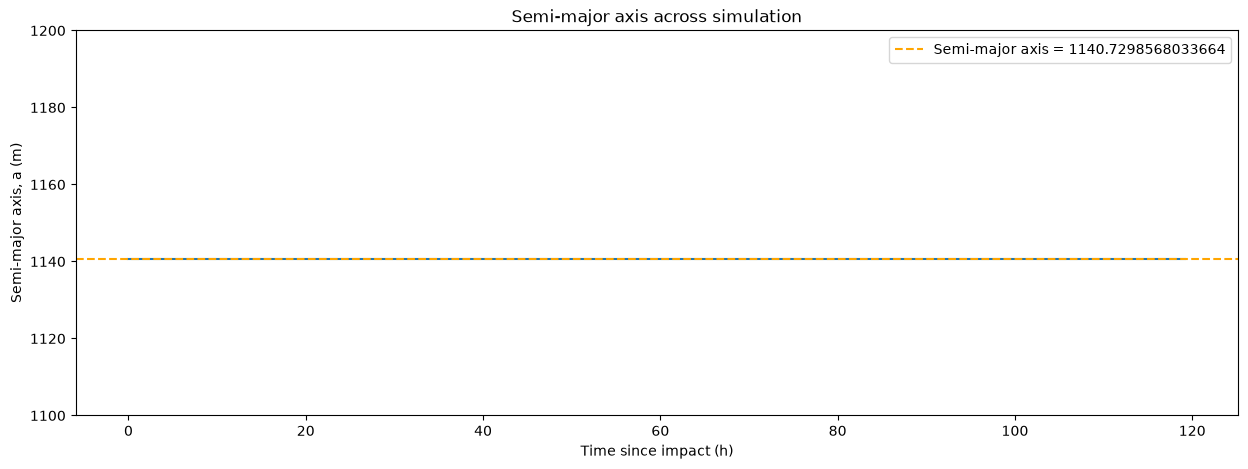

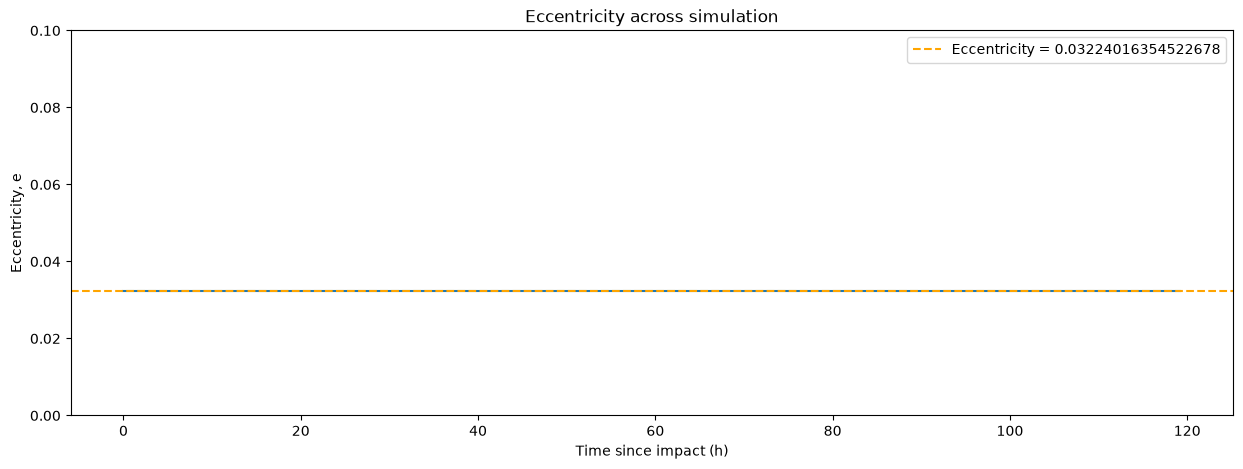

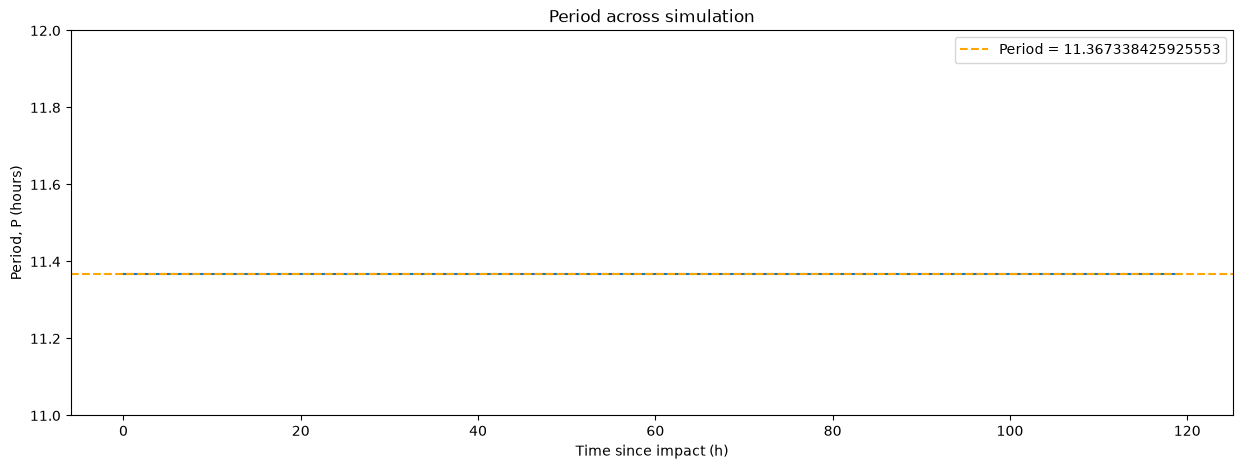

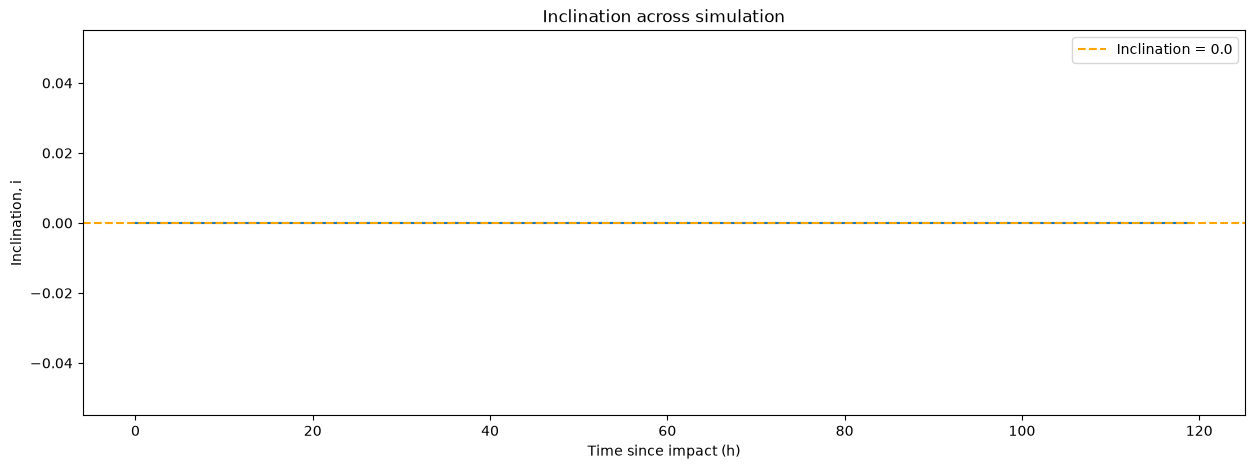

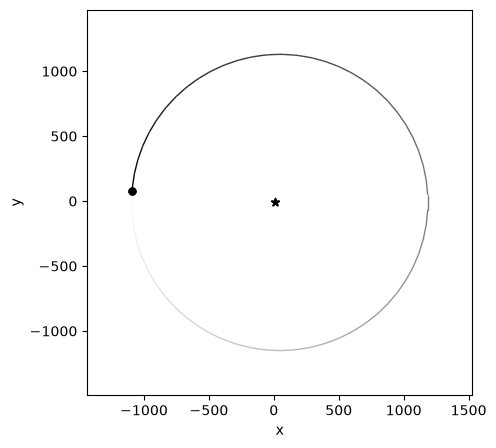

In [28]:
times_hours = times / (60 * 60)

%matplotlib inline
fig = plt.figure(figsize=(15,5))
ax = plt.subplot(111)
plt.plot(times_hours, a_values)
plt.axhline(a_values[-1], label="Semi-major axis = "+str(a_values[-1]), color="orange", linestyle="--")
plt.xlabel("Time since impact (h)")
plt.ylabel("Semi-major axis, a (m)")
plt.ylim(1100,1200)
plt.title("Semi-major axis across simulation")
plt.legend()
plt.show()

%matplotlib inline
fig = plt.figure(figsize=(15,5))
ax = plt.subplot(111)
plt.plot(times_hours, eccentricity_values)
plt.axhline(eccentricity_values[-1], label="Eccentricity = "+str(eccentricity_values[-1]), color="orange", linestyle="--")
plt.xlabel("Time since impact (h)")
plt.ylabel("Eccentricity, e")
plt.ylim(0, 0.1)
plt.title("Eccentricity across simulation")
plt.legend()
plt.show()

%matplotlib inline
fig = plt.figure(figsize=(15,5))
ax = plt.subplot(111)
period_values_hours = np.array(period_values) / (60 * 60)
plt.plot(times_hours, period_values_hours)
plt.axhline(period_values_hours[-1], label="Period = "+str(period_values_hours[-1]), color="orange", linestyle="--")
plt.xlabel("Time since impact (h)")
plt.ylabel("Period, P (hours)")
plt.ylim(11,12)
plt.title("Period across simulation")
plt.legend()
plt.show()

%matplotlib inline
fig = plt.figure(figsize=(15,5))
ax = plt.subplot(111)
plt.plot(times_hours, inclination_values)
plt.axhline(inclination_values[-1], label="Inclination = "+str(inclination_values[-1]), color="orange", linestyle="--")
plt.xlabel("Time since impact (h)")
plt.ylabel("Inclination, i")
plt.title("Inclination across simulation")
plt.legend()
plt.show()

%matplotlib inline
op = rebound.OrbitPlot(sim)